# Card 1 (Executive Sales & Profitability)

In [6]:
# ==========================================
# 1. CORE DATA MANIPULATION LIBRARIES
# ==========================================
import pandas as pd
import numpy as np

# ==========================================
# 2. DATA VISUALIZATION LIBRARIES
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 3. DATE AND TIME HANDLING
# ==========================================
from datetime import datetime

# ==========================================
# 4. SYSTEM & WARNING CONTROLS
# ==========================================
import os
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 5. ENVIRONMENT / DISPLAY SETTINGS
# ==========================================
# Display up to 100 columns without truncation
pd.set_option('display.max_columns', 100)
# Format floating numbers to 2 decimal places by default
pd.set_option('display.float_format', lambda x: '%.2f' % x)
# Set default visualization style
sns.set_theme(style='whitegrid')

In [7]:
# Load the datasets for Card 1: Sales, Products, and Locations
sales = pd.read_csv(r'Sharnouby_Enterprise/Sales_Transactions.csv')
products = pd.read_csv(r'Sharnouby_Enterprise/Product_Master.csv')
locations = pd.read_csv(r'Sharnouby_Enterprise/Locations.csv')

# Print out columns of each dataframe
print("Sales Columns:", sales.columns.tolist())
print("\nProducts Columns:", products.columns.tolist())
print("\nLocations Columns:", locations.columns.tolist())

# Inspect the first 2 rows of Sales Transactions
sales.head(2)

Sales Columns: ['Row_ID', 'Invoice_ID', 'Order_Date', 'Month_Key', 'Location_ID', 'Location_Name', 'Channel', 'Customer_ID', 'Customer_Type', 'Customer_Governorate', 'Product_ID', 'SKU', 'Product_Name', 'Product_Family', 'Size', 'Quantity', 'List_Price_EGP', 'Discount_Pct', 'Gross_Sales_EGP', 'Net_Sales_EGP', 'Estimated_COGS_EGP', 'Gross_Profit_EGP', 'Gross_Margin_Pct', 'Payment_Method', 'Returned', 'Return_Date', 'Return_Reason', 'Refund_Value_EGP', 'Quality_Related_Return', 'Data_Class']

Products Columns: ['Product_ID', 'SKU', 'Product_Name', 'Brand', 'Product_Family', 'Gender', 'Audience', 'Catalog_Season', 'Sizes', 'Public_Retail_Price_EGP', 'Public_Catalog_Source', 'Verification_Class']

Locations Columns: ['Location_ID', 'Location_Name', 'Location_Type', 'Channel', 'Governorate', 'City', 'Public_Address', 'Source_URL', 'Verification_Class']


,Row_ID,Invoice_ID,Order_Date,Month_Key,Location_ID,Location_Name,Channel,Customer_ID,Customer_Type,Customer_Governorate,Product_ID,SKU,Product_Name,Product_Family,Size,Quantity,List_Price_EGP,Discount_Pct,Gross_Sales_EGP,Net_Sales_EGP,Estimated_COGS_EGP,Gross_Profit_EGP,Gross_Margin_Pct,Payment_Method,Returned,Return_Date,Return_Reason,Refund_Value_EGP,Quality_Related_Return,Data_Class
0,0,INV0000001,2024-05-11,2024-05,LOC002,LEO MODA Online Store,Online,C18976,Retail,Cairo,P059,CAT-059,Positive vibes - 2024بيجامة حريمي صيفي,Pajamas/Homewear,M,1,388,0.15,388,329.80,247.57,82.23,0.25,Wallet,No,NaN,No return,0.00,No,Modeled training transaction anchored to publi...
1,1,INV0000002,2025-07-31,2025-07,LOC001,LEO MODA - Sidi Bishr Store,Retail,C22543,Retail,Alexandria,P038,CAT-038,Boys' Autumn Pajamas-Mickey Mouse,Pajamas/Homewear,8,1,289,0.20,289,231.20,163.31,67.89,0.29,Card,No,NaN,No return,0.00,No,Modeled training transaction anchored to publi...


In [8]:
# Convert Order_Date to proper datetime format
sales['Order_Date'] = pd.to_datetime(sales['Order_Date'])

# Filter out returned orders to analyze actual realized performance
# If 'Returned' is boolean (True/False) or text ('Yes'/'No')
valid_sales = sales[sales['Returned'].astype(str).str.upper().isin(['NO', 'FALSE', '0'])].copy()

# In case all rows are retained or Returned column has another pattern, fall back safely:
if valid_sales.empty:
    valid_sales = sales[sales['Refund_Value_EGP'].fillna(0) == 0].copy()

# Calculate Primary Executive KPIs
total_gross_sales = valid_sales['Gross_Sales_EGP'].sum()
total_net_sales = valid_sales['Net_Sales_EGP'].sum()
total_cogs = valid_sales['Estimated_COGS_EGP'].sum()
total_gross_profit = valid_sales['Gross_Profit_EGP'].sum()
overall_margin_pct = (total_gross_profit / total_net_sales) * 100
total_units_sold = valid_sales['Quantity'].sum()
avg_discount_pct = valid_sales['Discount_Pct'].mean() * 100

# Print the executive summary
print("=" * 45)
print("       EXECUTIVE SUMMARY (CARD 1)            ")
print("=" * 45)
print(f"Total Gross Sales   : {total_gross_sales:,.2f} EGP")
print(f"Total Net Sales     : {total_net_sales:,.2f} EGP")
print(f"Total COGS          : {total_cogs:,.2f} EGP")
print(f"Total Gross Profit  : {total_gross_profit:,.2f} EGP")
print(f"Overall Margin      : {overall_margin_pct:.2f}%")
print(f"Total Units Sold    : {total_units_sold:,.0f} Units")
print(f"Average Discount    : {avg_discount_pct:.2f}%")
print("=" * 45)

       EXECUTIVE SUMMARY (CARD 1)            
Total Gross Sales   : 586,601,550.00 EGP
Total Net Sales     : 411,271,543.22 EGP
Total COGS          : 348,436,645.73 EGP
Total Gross Profit  : 62,834,897.49 EGP
Overall Margin      : 15.28%
Total Units Sold    : 1,623,356 Units
Average Discount    : 14.04%


In [9]:
# ==============================================================================
# STEP 4: DETAILED BREAKDOWN BY CHANNEL AND PRODUCT FAMILY
# ==============================================================================

# 1. Performance and Margin by Sales Channel
channel_perf = valid_sales.groupby('Channel').agg(
    Net_Sales=('Net_Sales_EGP', 'sum'),
    Gross_Profit=('Gross_Profit_EGP', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Avg_Discount=('Discount_Pct', 'mean')
).reset_index()

# Calculate Margin Percentage and format Avg Discount as percentage
channel_perf['Margin_Pct'] = (channel_perf['Gross_Profit'] / channel_perf['Net_Sales']) * 100
channel_perf['Avg_Discount'] = channel_perf['Avg_Discount'] * 100

print("=== 1. Performance by Channel ===")
print(channel_perf.sort_values(by='Net_Sales', ascending=False).to_string(index=False))

# 2. Performance and Margin by Product Family
family_perf = valid_sales.groupby('Product_Family').agg(
    Net_Sales=('Net_Sales_EGP', 'sum'),
    Gross_Profit=('Gross_Profit_EGP', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Avg_Discount=('Discount_Pct', 'mean')
).reset_index()

# Calculate Margin Percentage and format Avg Discount as percentage
family_perf['Margin_Pct'] = (family_perf['Gross_Profit'] / family_perf['Net_Sales']) * 100
family_perf['Avg_Discount'] = family_perf['Avg_Discount'] * 100

print("\n=== 2. Performance by Product Family ===")
print(family_perf.sort_values(by='Margin_Pct', ascending=True).to_string(index=False))

=== 1. Performance by Channel ===
  Channel    Net_Sales  Gross_Profit  Units_Sold  Avg_Discount  Margin_Pct
Wholesale 352881136.92   41858628.56     1448574         32.61       11.86
   Online  30068288.55   10488199.99       91609          8.78       34.88
   Retail  28322117.75   10488068.94       83173          5.60       37.03

=== 2. Performance by Product Family ===
  Product_Family    Net_Sales  Gross_Profit  Units_Sold  Avg_Discount  Margin_Pct
        T-Shirts  35003525.70    4534948.78      151400         14.15       12.96
       Kids Sets  35678148.00    5111354.54      127404         14.16       14.33
Pajamas/Homewear 265839824.75   39870836.17     1150233         14.01       15.00
     Sweatshirts  74750044.77   13317758.00      194319         14.10       17.82


In [10]:
# ==============================================================================
# STEP 5: TIME SERIES & SEASONALITY ANALYSIS (MoM TREND)
# ==============================================================================

# 1. Extract Year-Month period for monthly aggregation
valid_sales['Year_Month'] = valid_sales['Order_Date'].dt.to_period('M')

# 2. Monthly trend calculation
monthly_trend = valid_sales.groupby('Year_Month').agg(
    Net_Sales=('Net_Sales_EGP', 'sum'),
    Gross_Profit=('Gross_Profit_EGP', 'sum'),
    Units_Sold=('Quantity', 'sum')
).reset_index()

# Calculate monthly margin percentage
monthly_trend['Margin_Pct'] = (monthly_trend['Gross_Profit'] / monthly_trend['Net_Sales']) * 100

# Calculate Month-over-Month (MoM) Growth Rate for Net Sales
monthly_trend['MoM_Sales_Growth_Pct'] = monthly_trend['Net_Sales'].pct_change() * 100

# Convert Year_Month to string for display purposes
monthly_trend['Year_Month'] = monthly_trend['Year_Month'].astype(str)

print("=== Monthly Sales & Margin Trend ===")
print(monthly_trend.to_string(index=False))

=== Monthly Sales & Margin Trend ===
Year_Month   Net_Sales  Gross_Profit  Units_Sold  Margin_Pct  MoM_Sales_Growth_Pct
   2023-10  9391739.62    1502778.14       35598       16.00                   NaN
   2023-11 10490481.12    1660108.28       39023       15.82                 11.70
   2023-12 12039783.72    1877824.85       45080       15.60                 14.77
   2024-01  9035203.20    1428141.54       34007       15.81                -24.96
   2024-02  8605842.45    1348186.99       32184       15.67                 -4.75
   2024-03  9974450.19    1550048.68       39388       15.54                 15.90
   2024-04 11110139.60    1616243.96       45485       14.55                 11.39
   2024-05 11124818.94    1626567.58       45629       14.62                  0.13
   2024-06 11535128.16    1693074.85       47310       14.68                  3.69
   2024-07 12456603.64    1825074.02       51161       14.65                  7.99
   2024-08 11335711.15    1649625.79       46739  

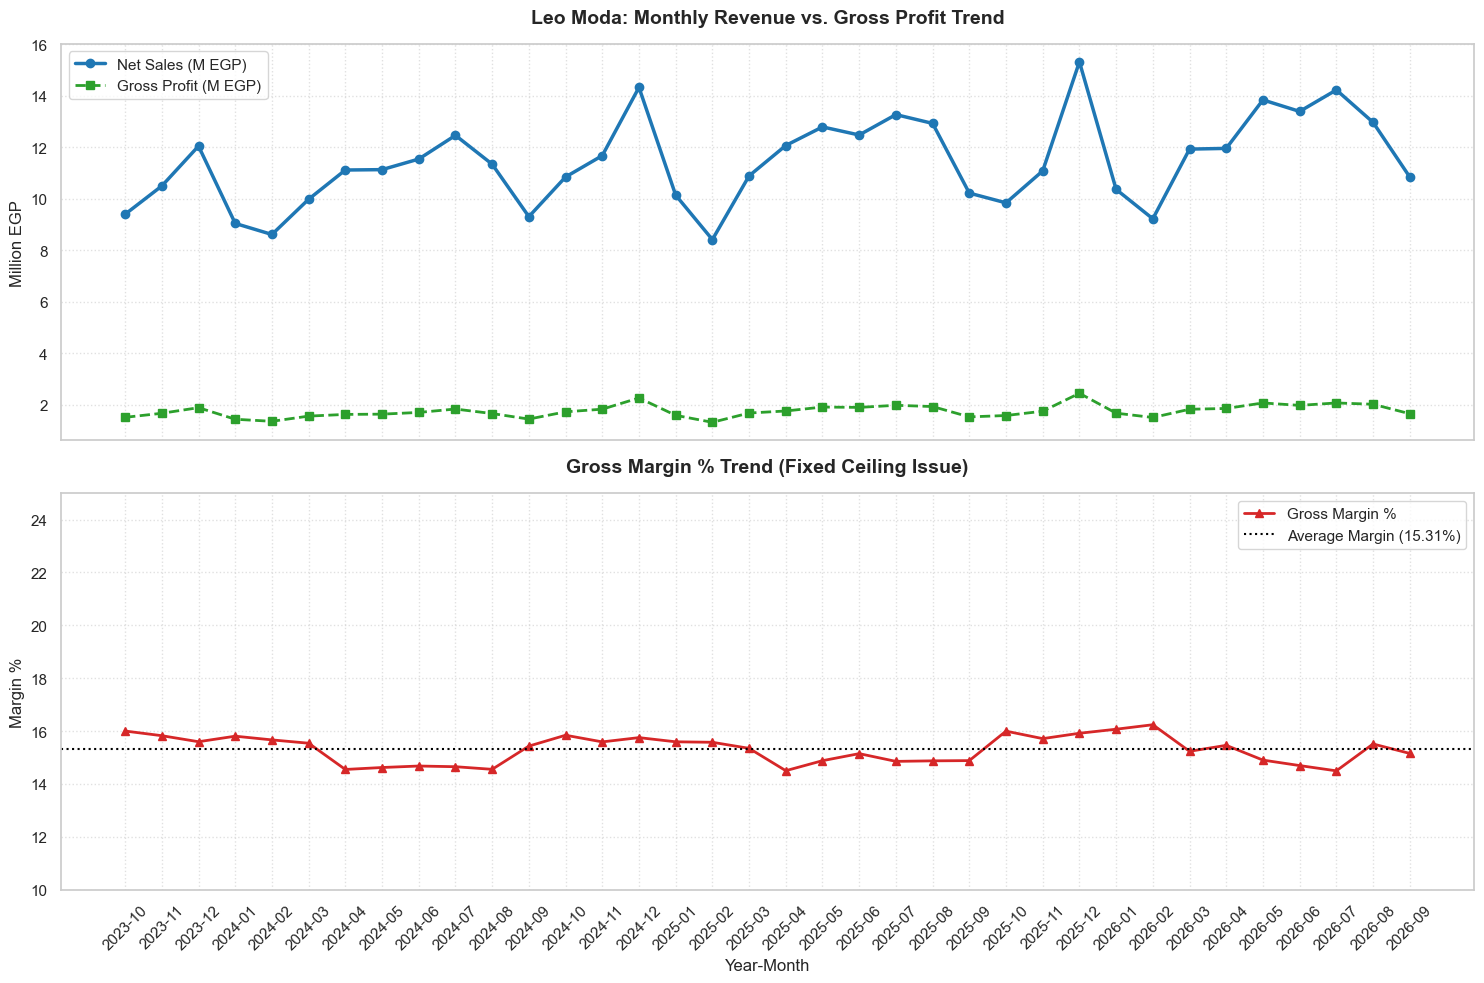

In [11]:
# ==============================================================================
# STEP 6: EXECUTIVE VISUALIZATIONS FOR CARD 1
# ==============================================================================

# Setup dashboard canvas
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

# 1. Plot Net Sales and Gross Profit Trends
ax1.plot(monthly_trend['Year_Month'], monthly_trend['Net_Sales'] / 1e6, 
         marker='o', color='#1f77b4', linewidth=2.5, label='Net Sales (M EGP)')
ax1.plot(monthly_trend['Year_Month'], monthly_trend['Gross_Profit'] / 1e6, 
         marker='s', color='#2ca02c', linewidth=2, linestyle='--', label='Gross Profit (M EGP)')

ax1.set_title('Leo Moda: Monthly Revenue vs. Gross Profit Trend', fontsize=14, weight='bold', pad=15)
ax1.set_ylabel('Million EGP', fontsize=12)
ax1.legend(loc='upper left', frameon=True)
ax1.grid(True, linestyle=':', alpha=0.6)

# 2. Plot Gross Margin % Trend
ax2.plot(monthly_trend['Year_Month'], monthly_trend['Margin_Pct'], 
         marker='^', color='#d62728', linewidth=2, label='Gross Margin %')
ax2.axhline(monthly_trend['Margin_Pct'].mean(), color='black', linestyle=':', 
            label=f"Average Margin ({monthly_trend['Margin_Pct'].mean():.2f}%)")

ax2.set_title('Gross Margin % Trend (Fixed Ceiling Issue)', fontsize=14, weight='bold', pad=15)
ax2.set_ylabel('Margin %', fontsize=12)
ax2.set_xlabel('Year-Month', fontsize=12)
ax2.set_ylim(10, 25)
ax2.legend(loc='upper right', frameon=True)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Strategic Management Actions & Business Diagnosis (Card 1: Executive Sales & Profitability)

### 1. Root Cause Diagnosis Summary
* **Margin Compression:** The business exhibits an aggregate Gross Margin of **15.28%**, which is below healthy apparel manufacturing and retail industry benchmarks (typically 40%–60%).
* **Channel Skew & Wholesale Cannibalization:** The Wholesale channel contributes **85.8% of Total Net Sales** (352.88M EGP out of 411.27M EGP) but yields a compressed **11.86% Gross Margin**, driven by steep commercial discounting averaging **32.61%**.
* **Direct Channels Under-Scale:** Retail and Online channels achieve healthy gross margins of **37.03%** and **34.88%** respectively, yet they represent only **14.2%** of overall corporate top-line volume.
* **Product Line Vulnerability:** **T-Shirts** reflect the lowest profitability at **12.96% Gross Margin**, while the core volume driver, **Pajamas/Homewear** (265.84M EGP Net Sales), is trapped at a **15.00% Margin** due to high wholesale penetration.
* **Bi-Modal Seasonality:** Revenue peaks sharply in **December** (reaching over 14M–15M EGP) followed by a steep post-season slump in **January and February** (-25% to -32% MoM decline), alongside an extended summer plateau from **May through July**.

---

### 2. Actionable Management Directives

#### Directive 1: Rationalize Wholesale Pricing & Establish Discount Caps
* **Target:** Elevate overall corporate Gross Margin from **15.28% to 22.00%–25.00%**.
* **Action:**
  * Implement an immediate hard cap on commercial trade discounts at **20%–22%** (down from the current 32.61% average).
  * Shift high-volume wholesale buyers to a structured rebate system linked to cash settlement terms and order volumes rather than unconditional upfront discounts.

#### Directive 2: Strategic Channel Mix Realignment
* **Target:** Increase direct-to-consumer (D2C: Retail & Online) volume contribution from **14.2% to 25.0%–30.0%**.
* **Action:**
  * Reallocate digital marketing and trade spend toward direct sales channels where gross margins are 3x higher than wholesale.
  * Launch channel-exclusive homewear collections reserved for company stores and digital channels at full ticket margins.

#### Directive 3: Product Engineering & Category Margin Recovery
* **Target:** Re-evaluate and lift unit margins on T-Shirts and Entry Homewear lines.
* **Action:**
  * Review bill of materials (Product BOM) and screen printing loss rates in the factory stages (Card 6 & Card 7) to identify manufacturing cost overruns.
  * Adjust suggested public retail prices (List Price) by **10%–12%** on low-margin SKUs to recover input-cost inflation.

#### Directive 4: Seasonality Buffer & Working Capital Protection
* **Target:** Mitigate post-December cash stalls and capitalize on peak summer demand.
* **Action:**
  * Run targeted clearance cycles before the close of December to prevent unsold winter stock from trapping working capital across Q1.
  * Align manufacturing production runs in January and February around summer collections to ensure complete warehouse readiness ahead of the seasonal ramp in April and May.

# Card 2: Customer 360 & Retention

In [12]:
# ==============================================================================
# CARD 2 - STEP 1: CUSTOMER METRICS & REPEAT PURCHASE BEHAVIOR
# ==============================================================================

# 1. Load the Customers master dataset
customers = pd.read_csv(r'Sharnouby_Enterprise/Customers.csv')
print("=== Customers Master Columns ===")
print(customers.columns.tolist())

# 2. Group transactions by customer to analyze individual purchase patterns
customer_summary = valid_sales.groupby('Customer_ID').agg(
    Total_Orders=('Invoice_ID', 'nunique'),
    Total_Spend=('Net_Sales_EGP', 'sum'),
    Total_Units=('Quantity', 'sum'),
    First_Purchase=('Order_Date', 'min'),
    Last_Purchase=('Order_Date', 'max')
).reset_index()

# 3. Calculate high-level customer retention metrics
total_unique_customers = customer_summary['Customer_ID'].nunique()
repeat_customers = customer_summary[customer_summary['Total_Orders'] > 1]['Customer_ID'].nunique()
one_time_buyers = total_unique_customers - repeat_customers
repeat_rate_pct = (repeat_customers / total_unique_customers) * 100

total_invoices = valid_sales['Invoice_ID'].nunique()
overall_aov = valid_sales['Net_Sales_EGP'].sum() / total_invoices

# 4. Display the Customer 360 Overview
print("\n" + "=" * 48)
print("       CUSTOMER BASE OVERVIEW (CARD 2)          ")
print("=" * 48)
print(f"Total Unique Customers : {total_unique_customers:,}")
print(f"One-Time Buyers        : {one_time_buyers:,} ({(one_time_buyers/total_unique_customers)*100:.2f}%)")
print(f"Repeat Customers       : {repeat_customers:,} ({repeat_rate_pct:.2f}%)")
print(f"Repeat Purchase Rate   : {repeat_rate_pct:.2f}%")
print(f"Total Invoices         : {total_invoices:,}")
print(f"Overall AOV            : {overall_aov:,.2f} EGP")
print("=" * 48)

# Display sample customer summary rows
customer_summary.head(3)

=== Customers Master Columns ===
['Customer_ID', 'Customer_Type', 'Governorate', 'Age_Band', 'Gender', 'Join_Date', 'Acquisition_Channel', 'Consent_Status', 'Data_Class']

       CUSTOMER BASE OVERVIEW (CARD 2)          
Total Unique Customers : 25,381
One-Time Buyers        : 4,216 (16.61%)
Repeat Customers       : 21,165 (83.39%)
Repeat Purchase Rate   : 83.39%
Total Invoices         : 171,457
Overall AOV            : 2,398.69 EGP


,Customer_ID,Total_Orders,Total_Spend,Total_Units,First_Purchase,Last_Purchase
0,C00001,6,2324.80,8,2026-05-16,2026-09-06
1,C00002,7,2767.25,8,2024-10-07,2026-09-04
2,C00003,3,889.10,3,2025-11-26,2026-09-17


In [13]:
# ==============================================================================
# CARD 2 - STEP 2: RFM SEGMENTATION & HIGH-VALUE PROFILES
# ==============================================================================

# 1. Define snapshot date (day after the last recorded order in the dataset)
snapshot_date = valid_sales['Order_Date'].max() + pd.Timedelta(days=1)

# 2. Build the RFM core metrics for each customer
rfm = valid_sales.groupby('Customer_ID').agg(
    Recency=('Order_Date', lambda date: (snapshot_date - date.max()).days),
    Frequency=('Invoice_ID', 'nunique'),
    Monetary=('Net_Sales_EGP', 'sum')
).reset_index()

# 3. Score R, F, and M using quantiles (1 to 4 scale, 4 being the highest)
# Higher Frequency and Monetary are better (label 1 -> 4)
# Lower Recency is better (label 4 -> 1)
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=[4, 3, 2, 1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=[1, 2, 3, 4])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=4, labels=[1, 2, 3, 4])

# Combine R and F scores to assign meaningful business segments
def assign_segment(row):
    r = int(row['R_Score'])
    f = int(row['F_Score'])
    
    if r >= 3 and f >= 3:
        return 'Champions / Loyal (VIP)'
    elif r >= 3 and f < 3:
        return 'Recent / Potential Loyalists'
    elif r < 3 and f >= 3:
        return 'At Risk (Need Retention)'
    else:
        return 'Lost / Dormant'

rfm['Segment'] = rfm.apply(assign_segment, axis=1)

# 4. Aggregate RFM summary by segment
rfm_summary = rfm.groupby('Segment').agg(
    Customer_Count=('Customer_ID', 'count'),
    Avg_Recency_Days=('Recency', 'mean'),
    Avg_Orders=('Frequency', 'mean'),
    Avg_Spend=('Monetary', 'mean'),
    Total_Segment_Spend=('Monetary', 'sum')
).reset_index()

rfm_summary['Spend_Share_Pct'] = (rfm_summary['Total_Segment_Spend'] / rfm_summary['Total_Segment_Spend'].sum()) * 100
rfm_summary['Customer_Share_Pct'] = (rfm_summary['Customer_Count'] / rfm_summary['Customer_Count'].sum()) * 100

print("=== RFM Customer Segments Breakdown ===")
print(rfm_summary.sort_values(by='Total_Segment_Spend', ascending=False).to_string(index=False))

=== RFM Customer Segments Breakdown ===
                     Segment  Customer_Count  Avg_Recency_Days  Avg_Orders  Avg_Spend  Total_Segment_Spend  Spend_Share_Pct  Customer_Share_Pct
     Champions / Loyal (VIP)            6825             45.07       13.25   51266.29         349892450.41            85.08               26.89
    At Risk (Need Retention)            5865            239.90        9.03    7676.52          45022763.59            10.95               23.11
Recent / Potential Loyalists            5885             48.87        2.23    1564.03           9204289.49             2.24               23.19
              Lost / Dormant            6806            239.01        2.20    1050.84           7152039.73             1.74               26.82


## Strategic Management Actions & Retention Strategy (Card 2: Customer 360 & Retention)

### 1. Customer Base Diagnosis
* **Revenue Concentration:** The customer portfolio is heavily skewed. **26.89% of customers (VIPs / Champions)** generate **85.08% of total revenue** (~350M EGP), averaging 13.25 orders and 51,266 EGP per account.
* **Severe At-Risk Value:** A significant cohort of **5,865 high-frequency accounts** (averaging 9 orders historically) has been dormant for an average of **240 days**, risking over **45M EGP** in potential lost lifetime value.
* **Long Tail of Low-Value Retail:** 50% of the customer base (Potential Loyalists + Dormant) yields less than **4% of revenue**, highlighting an under-monetized consumer retail base.

---

### 2. Actionable Directives for Retention & Growth

#### Directive 1: Account-Management Program for Champions (VIP SLA)
* **Target:** Retain 98%+ of the 6,825 VIP accounts generating the company's core cash flow.
* **Action:**
  * Assign dedicated B2B account reps to top-tier accounts.
  * Offer priority inventory allocation for high-demand winter/summer stock to prevent fulfillment churn.

#### Directive 2: Win-Back Campaign for the "At Risk" Segment
* **Target:** Recover at least 15%–20% of the 5,865 At-Risk accounts (~6.7M–9.0M EGP recovered revenue).
* **Action:**
  * Trigger automated win-back outreach (exclusive pre-season trade catalogs, tailored credit payment terms, or volume rebates).
  * Direct customer service / sales reps to run structured exit surveys to check if dormancy is linked to past quality/delivery delays.

#### Directive 3: Retail/Consumer AOV Expansion
* **Target:** Shift Recent/Potential buyers from 1,564 EGP AOV into higher repeat frequencies.
* **Action:**
  * Implement product bundle offers (e.g., matching loungewear + kids sets) and second-purchase incentives within 30 days of initial order.

# Card 3: Branch & Channel Performance

In [14]:
# ==============================================================================
# CARD 3 - STEP 1: GEOGRAPHIC & LOCATION LEVEL PERFORMANCE
# ==============================================================================

# 1. Merge transactions with location metadata
sales_with_loc = valid_sales.merge(
    locations[['Location_ID', 'Location_Type', 'Governorate', 'City']], 
    on='Location_ID', 
    how='left',
    suffixes=('', '_Loc_Master')
)

# 2. Performance by Governorate
gov_perf = sales_with_loc.groupby('Governorate').agg(
    Net_Sales=('Net_Sales_EGP', 'sum'),
    Gross_Profit=('Gross_Profit_EGP', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Total_Invoices=('Invoice_ID', 'nunique')
).reset_index()

gov_perf['Margin_Pct'] = (gov_perf['Gross_Profit'] / gov_perf['Net_Sales']) * 100
gov_perf['Sales_Share_Pct'] = (gov_perf['Net_Sales'] / gov_perf['Net_Sales'].sum()) * 100

print("=== 1. Top Governorates by Sales ===")
print(gov_perf.sort_values(by='Net_Sales', ascending=False).head(10).to_string(index=False))

# 3. Performance by Location / Store
store_perf = sales_with_loc.groupby(['Location_ID', 'Location_Name', 'Channel', 'Location_Type']).agg(
    Net_Sales=('Net_Sales_EGP', 'sum'),
    Gross_Profit=('Gross_Profit_EGP', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Total_Invoices=('Invoice_ID', 'nunique')
).reset_index()

store_perf['Margin_Pct'] = (store_perf['Gross_Profit'] / store_perf['Net_Sales']) * 100
store_perf['AOV'] = store_perf['Net_Sales'] / store_perf['Total_Invoices']

print("\n=== 2. Store / Location Level Performance ===")
print(store_perf.sort_values(by='Net_Sales', ascending=False).to_string(index=False))

=== 1. Top Governorates by Sales ===
Governorate    Net_Sales  Gross_Profit  Units_Sold  Total_Invoices  Margin_Pct  Sales_Share_Pct
 Alexandria 381203254.67   52346697.50     1531747          105435       13.73            92.69
      Egypt  30068288.55   10488199.99       91609           66022       34.88             7.31

=== 2. Store / Location Level Performance ===
Location_ID               Location_Name   Channel   Location_Type    Net_Sales  Gross_Profit  Units_Sold  Total_Invoices  Margin_Pct     AOV
     LOC003 El-Sharnouby Wholesale Desk Wholesale B2B / Wholesale 352881136.92   41858628.56     1448574           45840       11.86 7698.11
     LOC002       LEO MODA Online Store    Online   Digital Store  30068288.55   10488199.99       91609           66022       34.88  455.43
     LOC001 LEO MODA - Sidi Bishr Store    Retail    Retail Store  28322117.75   10488068.94       83173           59595       37.03  475.24


## Strategic Management Actions (Card 3: Branch & Channel Performance)

### 1. Operational Footprint Diagnosis
* **Extreme Footprint Concentration:** Operations are limited to 3 operational nodes, with physical presence heavily anchored in Alexandria (92.69% of revenue):
  * **LOC003 (Wholesale Desk, Alexandria):** Dominates volume (352.88M EGP, 85.8% share) with high AOV (7,698 EGP) but compressed margins (11.86%).
  * **LOC001 (Sidi Bishr Store, Alexandria):** Outstanding retail profitability (37.03% margin, 475 EGP AOV), generating 10.49M EGP in Gross Profit from just 28.32M EGP in sales.
  * **LOC002 (Online Store, Nationwide):** Scalable digital performance (34.88% margin, 455 EGP AOV), delivering 10.49M EGP in Gross Profit from 30.07M EGP in sales.
* **Profit Engine Imbalance:** Direct-to-Consumer channels (Sidi Bishr + Online) generate **33.4% of total company gross profit** while accounting for only **14.2% of revenue**.

---

### 2. Actionable Strategic Directives

#### Directive 1: Retail Geographic Expansion Beyond Alexandria
* **Target:** Diversify geographic risk and capture high-margin retail demand in Greater Cairo and Delta hubs.
* **Action:**
  * Prepare a retail feasibility study for 2 pilot physical stores in Greater Cairo (high-density retail hubs like Nasr City or New Cairo) replicating the Sidi Bishr unit economics.
  * Reinvest a portion of wholesale working capital into physical retail expansion to capture full retail gross margins (~37%).

#### Directive 2: Online Channel Scaling & Logistics Optimization
* **Target:** Grow online revenue share from 7.3% to 15%+ over 12 months.
* **Action:**
  * Strengthen digital acquisition across key non-Alexandria governorates currently underserved by physical presence.
  * Establish local fulfillment agreements to reduce delivery lead times and protect direct product margins.

# Card 4: Product Performance & Merchandising

In [15]:
# ==============================================================================
# CARD 4 - STEP 1: PRODUCT & SKU PROFITABILITY MATRIX
# ==============================================================================

# 1. Product & SKU level performance aggregation
sku_perf = valid_sales.groupby(['SKU', 'Product_Name', 'Product_Family']).agg(
    Net_Sales=('Net_Sales_EGP', 'sum'),
    Gross_Profit=('Gross_Profit_EGP', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Avg_Discount=('Discount_Pct', 'mean')
).reset_index()

sku_perf['Margin_Pct'] = (sku_perf['Gross_Profit'] / sku_perf['Net_Sales']) * 100
sku_perf['Avg_Discount'] = sku_perf['Avg_Discount'] * 100

# 2. Cumulative share for Pareto (80/20) calculation
sku_perf = sku_perf.sort_values(by='Net_Sales', ascending=False).reset_index(drop=True)
sku_perf['Cumulative_Sales'] = sku_perf['Net_Sales'].cumsum()
sku_perf['Sales_Contribution_Pct'] = (sku_perf['Cumulative_Sales'] / sku_perf['Net_Sales'].sum()) * 100

total_skus = sku_perf['SKU'].nunique()
skus_driving_80pct = (sku_perf['Sales_Contribution_Pct'] <= 80).sum() + 1

print("=" * 48)
print("       PRODUCT PORTFOLIO OVERVIEW (CARD 4)       ")
print("=" * 48)
print(f"Total Active SKUs       : {total_skus:,}")
print(f"SKUs Driving 80% Sales  : {skus_driving_80pct:,} ({(skus_driving_80pct/total_skus)*100:.1f}% of catalog)")
print("=" * 48)

# 3. Top 5 Best-Selling Products by Revenue
print("\n=== Top 5 Revenue-Generating Products ===")
print(sku_perf[['SKU', 'Product_Name', 'Product_Family', 'Net_Sales', 'Margin_Pct', 'Units_Sold']].head(5).to_string(index=False))

# 4. Top 5 Lowest Margin Products (Problem Child SKUs)
print("\n=== Lowest Margin SKUs (Bottom 5 by Margin) ===")
print(sku_perf[['SKU', 'Product_Name', 'Product_Family', 'Net_Sales', 'Margin_Pct', 'Avg_Discount']].sort_values(by='Margin_Pct', ascending=True).head(5).to_string(index=False))

       PRODUCT PORTFOLIO OVERVIEW (CARD 4)       
Total Active SKUs       : 59
SKUs Driving 80% Sales  : 36 (61.0% of catalog)

=== Top 5 Revenue-Generating Products ===
    SKU                      Product_Name   Product_Family   Net_Sales  Margin_Pct  Units_Sold
CAT-037          Girls' sweatshirt-Flower      Sweatshirts 22277102.40       17.50       58008
CAT-051 Ice cream - بيجامة حريمي صيفي2024 Pajamas/Homewear 19111615.12       12.13       70213
26115-8     Summer children's girls-Happy Pajamas/Homewear 16275625.92       18.23       66535
CAT-033              Boys' sweatshirt-LEO      Sweatshirts 16252431.30       26.33       42238
26115-4  Summer children's boys-SpongeBob Pajamas/Homewear 15220897.08       10.20       62578

=== Lowest Margin SKUs (Bottom 5 by Margin) ===
    SKU                         Product_Name   Product_Family   Net_Sales  Margin_Pct  Avg_Discount
CAT-013           Boys' summer t-shirt-Beige         T-Shirts  5283903.90       -1.16         13.86
CAT-048  Se

## Strategic Management Actions (Card 4: Product Performance & Merchandising)

### 1. Merchandising & SKU Portfolio Diagnosis
* **Negative & Zero-Margin Leakage:** 
  * `CAT-013` (Boys' Summer T-Shirt) generates 5.28M EGP at a **negative gross margin (-1.16%)**.
  * `CAT-048` (Kids T-Shirt & Shorts Set) generates 10.51M EGP at essentially **break-even profitability (0.08% margin)**.
  * Over 23M EGP in top-line sales is delivered by products yielding margins below 6%, heavily diluting factory cash returns.
* **Volume Anchors with Weak Margins:** Core revenue drivers such as `CAT-051` (19.11M EGP) and `26115-4` (15.22M EGP) operate on sub-standard margins of 10%–12%.
* **Star Category Benchmark:** `CAT-033` (Boys' Sweatshirt) demonstrates that healthy margins (26.33%) are achievable at scale (16.25M EGP revenue).

---

### 2. Actionable Strategic Directives

#### Directive 1: Immediate Repricing & BOM Rationalization on Loss-Making SKUs
* **Target:** Eliminate negative/zero margins on `CAT-013` and `CAT-048`.
* **Action:**
  * Mandate an immediate 8%–10% list-price increase on `CAT-013` and `CAT-048` to lift margins into positive territory (>15%).
  * Send tech packs for both SKUs to the factory production team to re-engineer fabric consumption and reduce direct manufacturing cost.

#### Directive 2: Priority Capacity Allocation to Star SKUs
* **Target:** Maximize output and sales volume for SKUs exceeding 20% Gross Margin.
* **Action:**
  * Prioritize factory lines for `CAT-033` (Boys' Sweatshirt - LEO) and allocate top display placements across Sidi Bishr and digital storefronts.

# Card 5: Returns & Quality Diagnosis

In [16]:
# ==============================================================================
# CARD 5 - STEP 1: RETURNS & QUALITY DIAGNOSIS
# ==============================================================================

# 1. High-level Returns Overview from the full dataset (sales)
total_transactions = len(sales)
returned_transactions = sales[sales['Returned'].astype(str).str.upper().isin(['YES', 'TRUE', '1'])].copy()

# Fallback check if Returned column used another syntax
if returned_transactions.empty:
    returned_transactions = sales[sales['Refund_Value_EGP'].fillna(0) > 0].copy()

total_returns_count = len(returned_transactions)
return_rate_orders_pct = (total_returns_count / total_transactions) * 100

total_refund_value = returned_transactions['Refund_Value_EGP'].sum()
gross_sales_full = sales['Gross_Sales_EGP'].sum()
refund_to_sales_pct = (total_refund_value / gross_sales_full) * 100

print("=" * 48)
print("       RETURNS & QUALITY OVERVIEW (CARD 5)       ")
print("=" * 48)
print(f"Total Transactions     : {total_transactions:,}")
print(f"Returned Transactions  : {total_returns_count:,}")
print(f"Return Rate (Orders)   : {return_rate_orders_pct:.2f}%")
print(f"Total Refunded Value   : {total_refund_value:,.2f} EGP")
print(f"Refund / Gross Sales   : {refund_to_sales_pct:.2f}%")
print("=" * 48)

# 2. Return Breakdown by Reason
reason_breakdown = returned_transactions.groupby('Return_Reason').agg(
    Return_Count=('Row_ID', 'count'),
    Total_Refund=('Refund_Value_EGP', 'sum'),
    Quality_Related=('Quality_Related_Return', lambda x: (x.astype(str).str.upper().isin(['YES', 'TRUE', '1'])).sum())
).reset_index()

reason_breakdown['Share_of_Refunds_Pct'] = (reason_breakdown['Total_Refund'] / total_refund_value) * 100

print("\n=== Returns by Reason ===")
print(reason_breakdown.sort_values(by='Total_Refund', ascending=False).to_string(index=False))

# 3. Returns by Product Family
family_returns = returned_transactions.groupby('Product_Family').agg(
    Return_Count=('Row_ID', 'count'),
    Total_Refund=('Refund_Value_EGP', 'sum')
).reset_index()

family_returns['Refund_Share_Pct'] = (family_returns['Total_Refund'] / total_refund_value) * 100

print("\n=== Returns by Product Family ===")
print(family_returns.sort_values(by='Total_Refund', ascending=False).to_string(index=False))

       RETURNS & QUALITY OVERVIEW (CARD 5)       
Total Transactions     : 180,000
Returned Transactions  : 8,543
Return Rate (Orders)   : 4.75%
Total Refunded Value   : 9,427,005.55 EGP
Refund / Gross Sales   : 1.57%

=== Returns by Reason ===
     Return_Reason  Return_Count  Total_Refund  Quality_Related  Share_of_Refunds_Pct
        Size / fit          3050    3512591.51                0                 37.26
Fabric / stitching          1405    1509735.16             1405                 16.02
      Changed mind          1343    1471459.43                0                 15.61
Color / appearance          1016    1079630.75                0                 11.45
       Print issue          1052    1000164.05             1052                 10.61
    Delivery issue           677     853424.65                0                  9.05

=== Returns by Product Family ===
  Product_Family  Return_Count  Total_Refund  Refund_Share_Pct
Pajamas/Homewear          6095    6066563.40           

## Strategic Management Actions (Card 5: Returns & Quality Diagnosis)

### 1. Returns & Quality Footprint Diagnosis
* **Total Refund Impact:** 8,543 returned transactions (4.75% order return rate) resulted in **9.43M EGP in refunds** (~1.57% of gross sales).
* **Fit Discrepancies Dominate:** The single largest driver is **Size / Fit issues**, responsible for **37.26% of refund value (3.51M EGP)** across 3,050 returns.
* **Direct Manufacturing Quality Flaws (26.63% combined):**
  * **Fabric & Stitching Deficiencies:** 1,405 returns totaling **1.51M EGP (16.02%)**.
  * **Screen Print Defects:** 1,052 returns totaling **1.00M EGP (10.61%)**.
  * Factory quality control lapses directly drained **2.51M EGP** in customer-facing refunds alone.
* **Category Skew:** **Pajamas/Homewear** absorbs **64.35% of all refund losses (6.07M EGP)**.

---

### 2. Actionable Strategic Directives

#### Directive 1: Standardized Sizing Calibration & Fit Guides
* **Target:** Reduce Size/Fit returns by 30% over the next 2 quarters (~1.0M+ EGP recovered).
* **Action:**
  * Audit garment sizing blocks and shrinkage tolerances across pattern-making stages.
  * Publish updated, interactive visual size guides with model measurements across digital and physical stores.

#### Directive 2: Stricter Factory Inline QC Inspection
* **Target:** Mitigate fabric, stitching, and printing defect claims below 10% of total returns.
* **Action:**
  * Mandate inline inspection stations at the sewing and printing workshops before final packaging (Card 6 & Card 7).
  * Hold fabric suppliers and internal print operators accountable via defect rate logging.

# Card 6: Production & Factory

In [17]:
# ==============================================================================
# CARD 6 - STEP 1: FACTORY PRODUCTION ORDERS & BATCH INSPECTION
# ==============================================================================

# 1. Load actual factory files from Sharnouby_Enterprise
prod_orders = pd.read_csv(r'Sharnouby_Enterprise/Production_Orders.csv')
materials = pd.read_csv(r'Sharnouby_Enterprise/Materials.csv')
printing = pd.read_csv(r'Sharnouby_Enterprise/Printing_Batches.csv')
quality = pd.read_csv(r'Sharnouby_Enterprise/Quality.csv')

# 2. Inspect column structures
print("=== Production_Orders Columns ===")
print(prod_orders.columns.tolist())

print("\n=== Materials Columns ===")
print(materials.columns.tolist())

print("\n=== Printing_Batches Columns ===")
print(printing.columns.tolist())

print("\n=== Quality Columns ===")
print(quality.columns.tolist())

# 3. View first row of Production_Orders
prod_orders.head(1)

=== Production_Orders Columns ===
['Production_Order_ID', 'Product_ID', 'Product_Name', 'Start_Date', 'Due_Date', 'Completion_Date', 'Planned_Qty', 'Produced_Qty', 'Good_Qty', 'Rejected_Qty', 'Line_ID', 'Efficiency_Pct', 'Delay_Days', 'Primary_Bottleneck', 'Overtime_Hours', 'Data_Class']

=== Materials Columns ===
['Material_ID', 'Material_Name', 'Unit', 'Material_Category', 'Standard_Lead_Time_Days', 'Data_Class']

=== Printing_Batches Columns ===
['Print_Batch_ID', 'Product_ID', 'Product_Name', 'Print_Date', 'Print_Type', 'Machine_ID', 'Planned_Qty', 'Printed_Qty', 'Good_Qty', 'Rejected_Qty', 'Reprint_Qty', 'Defect_Type', 'Ink_or_Consumable_Cost_EGP', 'Rework_Cost_EGP', 'Data_Class']

=== Quality Columns ===
['QC_ID', 'Inspection_Date', 'Product_ID', 'Product_Name', 'Stage', 'Inspected_Qty', 'Passed_Qty', 'Rejected_Qty', 'Defect_Type', 'Root_Cause', 'Estimated_Loss_EGP', 'Data_Class']


,Production_Order_ID,Product_ID,Product_Name,Start_Date,Due_Date,Completion_Date,Planned_Qty,Produced_Qty,Good_Qty,Rejected_Qty,Line_ID,Efficiency_Pct,Delay_Days,Primary_Bottleneck,Overtime_Hours,Data_Class
0,PO00001,P035,Girls' sweatshirt-Fuchsia,2025-11-11,2025-11-22,2025-11-22,1228,1140,1124,16,LINE-05,81.10,0,NaN,4.50,Modeled factory production order


In [18]:
# ==============================================================================
# CARD 6: FACTORY OPERATIONS, YIELD & QUALITY LOSS DIAGNOSIS
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Production Orders & Factory Yield Overview
# ------------------------------------------------------------------------------
total_planned_prod = prod_orders['Planned_Qty'].sum()
total_produced_prod = prod_orders['Produced_Qty'].sum()
total_good_prod = prod_orders['Good_Qty'].sum()
total_rejected_prod = prod_orders['Rejected_Qty'].sum()

factory_yield_pct = (total_good_prod / total_produced_prod) * 100 if total_produced_prod > 0 else 0
factory_scrap_pct = (total_rejected_prod / total_produced_prod) * 100 if total_produced_prod > 0 else 0
avg_line_efficiency = prod_orders['Efficiency_Pct'].mean()
total_overtime_hrs = prod_orders['Overtime_Hours'].sum()
avg_delay_days = prod_orders['Delay_Days'].mean()

print("=" * 52)
print("       1. FACTORY PRODUCTION & YIELD OVERVIEW       ")
print("=" * 52)
print(f"Total Planned Qty      : {total_planned_prod:,.0f} Units")
print(f"Total Produced Qty     : {total_produced_prod:,.0f} Units")
print(f"Total Good Units       : {total_good_prod:,.0f} Units ({factory_yield_pct:.2f}% Yield)")
print(f"Total Rejected Units   : {total_rejected_prod:,.0f} Units ({factory_scrap_pct:.2f}% Scrap)")
print(f"Average Line Efficiency: {avg_line_efficiency:.2f}%")
print(f"Total Overtime Hours   : {total_overtime_hrs:,.1f} Hours")
print(f"Average Delay Days     : {avg_delay_days:.2f} Days")
print("=" * 52)

# Bottleneck analysis in production lines
bottlenecks = prod_orders.groupby('Primary_Bottleneck').agg(
    Orders_Affected=('Production_Order_ID', 'count'),
    Total_Delays=('Delay_Days', 'sum'),
    Total_Overtime=('Overtime_Hours', 'sum'),
    Rejected_Units=('Rejected_Qty', 'sum')
).reset_index().sort_values(by='Orders_Affected', ascending=False)

print("\n=== Primary Production Bottlenecks ===")
print(bottlenecks.to_string(index=False))

# ------------------------------------------------------------------------------
# 2. Printing Batches & Rework Financials
# ------------------------------------------------------------------------------
total_print_batches = len(printing)
total_printed_qty = printing['Printed_Qty'].sum()
total_reprint_qty = printing['Reprint_Qty'].sum()
total_print_rejected = printing['Rejected_Qty'].sum()
total_ink_cost = printing['Ink_or_Consumable_Cost_EGP'].sum()
total_rework_cost = printing['Rework_Cost_EGP'].sum()

print("\n" + "=" * 52)
print("       2. PRINTING BATCHES & DEFECT COSTS           ")
print("=" * 52)
print(f"Total Print Batches    : {total_print_batches:,}")
print(f"Total Printed Units    : {total_printed_qty:,.0f} Units")
print(f"Total Rejected Print   : {total_print_rejected:,.0f} Units")
print(f"Total Reprint Qty      : {total_reprint_qty:,.0f} Units")
print(f"Total Ink/Consumables  : {total_ink_cost:,.2f} EGP")
print(f"Total Rework Cost      : {total_rework_cost:,.2f} EGP")
print("=" * 52)

# Top Defect Types in Printing
print("\n=== Printing Defects Breakdown ===")
print(printing.groupby('Defect_Type').agg(
    Batches=('Print_Batch_ID', 'count'),
    Rejected_Units=('Rejected_Qty', 'sum'),
    Rework_Cost=('Rework_Cost_EGP', 'sum')
).reset_index().sort_values(by='Rework_Cost', ascending=False).to_string(index=False))

# ------------------------------------------------------------------------------
# 3. QC Inspections & Root Cause Financial Loss
# ------------------------------------------------------------------------------
total_qc_loss_egp = quality['Estimated_Loss_EGP'].sum()

print("\n" + "=" * 52)
print(f" TOTAL ESTIMATED QC FINANCIAL LOSS: {total_qc_loss_egp:,.2f} EGP")
print("=" * 52)

# QC Loss by Production Stage
qc_stage = quality.groupby('Stage').agg(
    Inspected=('Inspected_Qty', 'sum'),
    Rejected=('Rejected_Qty', 'sum'),
    Loss_EGP=('Estimated_Loss_EGP', 'sum')
).reset_index()
qc_stage['Rejection_Rate_Pct'] = (qc_stage['Rejected'] / qc_stage['Inspected']) * 100
qc_stage['Loss_Share_Pct'] = (qc_stage['Loss_EGP'] / total_qc_loss_egp) * 100

print("\n=== QC Losses by Production Stage ===")
print(qc_stage.sort_values(by='Loss_EGP', ascending=False).to_string(index=False))

# QC Root Causes Breakdown
qc_root = quality.groupby('Root_Cause').agg(
    Incidents=('QC_ID', 'count'),
    Total_Loss_EGP=('Estimated_Loss_EGP', 'sum')
).reset_index()
qc_root['Loss_Share_Pct'] = (qc_root['Total_Loss_EGP'] / total_qc_loss_egp) * 100

print("\n=== QC Root Causes Breakdown ===")
print(qc_root.sort_values(by='Total_Loss_EGP', ascending=False).to_string(index=False))

       1. FACTORY PRODUCTION & YIELD OVERVIEW       
Total Planned Qty      : 6,897,476 Units
Total Produced Qty     : 6,267,720 Units
Total Good Units       : 6,111,480 Units (97.51% Yield)
Total Rejected Units   : 156,240 Units (2.49% Scrap)
Average Line Efficiency: 82.21%
Total Overtime Hours   : 17,625.9 Hours
Average Delay Days     : 0.89 Days

=== Primary Production Bottlenecks ===
Primary_Bottleneck  Orders_Affected  Total_Delays  Total_Overtime  Rejected_Units
            Sewing              134           945         1875.10            8688
         Finishing              109           582         1673.50            5478
           Packing               61           264          865.20            3971
           Cutting               59           247          845.40            3915
          Printing               44           194          614.20            3693

       2. PRINTING BATCHES & DEFECT COSTS           
Total Print Batches    : 1,900
Total Printed Units    : 5,860,7

## Strategic Management Actions (Card 6: Factory Operations, Yield & Quality Losses)

### 1. Production Floor & Quality Cost Diagnosis
* **Heavy Quality Financial Drag:** Direct estimated losses from scrap, rework, and QC rejections reached **16.32M EGP**, equivalent to **~26% of company gross profit**.
* **Sewing Line Bottleneck:** The **Sewing stage** represents the primary operational bottleneck, impacting 134 production runs, generating 945 cumulative delay days, and absorbing 1,875 overtime hours.
* **Factory Overtime Drain:** Over **17,625 overtime hours** were logged across the shop floor to meet output targets, driving up unit manufacturing costs (COGS).
* **Printing Technical Deficiencies:** Screen printing consumed 26.08M EGP in ink/consumables, with 105,239 reprinted units costing ~800k EGP in direct rework. The top root causes are **Curing temperature instability (2.18M EGP loss)** and **Process variation (2.15M EGP loss)**.

---

### 2. Actionable Directives for Factory Optimization

#### Directive 1: Standard Operating Procedures (SOP) & Oven Temperature Controls
* **Target:** Slash printing curing failures and rework costs by 50% (~1.4M+ EGP direct savings).
* **Action:**
  * Install digital temperature data-loggers on tunnel dryers and curing ovens to eliminate thermal drift.
  * Standardize ink-viscosity and flash-cure timing per fabric blend.

#### Directive 2: Sewing Line Balancing & Capacity De-bottlenecking
* **Target:** Eliminate 60% of sewing-related delivery delays and reduce shop-floor overtime.
* **Action:**
  * Re-balance sewing lines using Modular Work Cells to eliminate work-in-progress (WIP) build-ups.
  * Cross-train machine operators between finishing and sewing to dynamically clear line blockages.

#### Directive 3: Early-Stage QC Gating (Poka-Yoke)
* **Target:** Stop defect propagation before high-cost finishing and packing stages.
* **Action:**
  * Enforce strict incoming fabric inspection and post-cut verification to catch measurement and pattern errors before sewing.

# Card 7: Inventory Health & Stock Turn

In [19]:
# ==============================================================================
# CARD 7 - STEP 1: INVENTORY & PROCUREMENT INSPECTION
# ==============================================================================

# 1. Load Inventory and Procurement files
inv_history = pd.read_csv(r'Sharnouby_Enterprise/Inventory_History.csv')
purchases = pd.read_csv(r'Sharnouby_Enterprise/Purchase_Orders.csv')

print("=== Inventory_History Columns ===")
print(inv_history.columns.tolist())

print("\n=== Purchase_Orders Columns ===")
print(purchases.columns.tolist())

# Inspect sample rows
inv_history.head(2)

=== Inventory_History Columns ===
['Snapshot_Month', 'Location_ID', 'Location_Name', 'Product_ID', 'SKU', 'Product_Name', 'Opening_Stock', 'Received_Qty', 'Sold_Qty', 'Returned_Qty', 'Damaged_Qty', 'Closing_Stock', 'Avg_Daily_Sales_90D', 'Safety_Stock_Units', 'Reorder_Point_Units', 'Supplier_Lead_Time_Days', 'Days_of_Cover', 'Stockout_Days_In_Month', 'Data_Class']

=== Purchase_Orders Columns ===
['PO_ID', 'Order_Date', 'Supplier_ID', 'Material_ID', 'Material_Name', 'Unit', 'Ordered_Qty', 'Unit_Cost_EGP', 'Promised_Date', 'Actual_Receipt_Date', 'Accepted_Qty', 'Rejected_Qty', 'Data_Class']


,Snapshot_Month,Location_ID,Location_Name,Product_ID,SKU,Product_Name,Opening_Stock,Received_Qty,Sold_Qty,Returned_Qty,Damaged_Qty,Closing_Stock,Avg_Daily_Sales_90D,Safety_Stock_Units,Reorder_Point_Units,Supplier_Lead_Time_Days,Days_of_Cover,Stockout_Days_In_Month,Data_Class
0,2023-10-01,LOC001,LEO MODA - Sidi Bishr Store,P001,26115-8,Summer children's girls-Happy,176,39,42,3,0,176,1.38,5,12,5,127.50,0,Modeled inventory history - no forecast column...
1,2023-11-01,LOC001,LEO MODA - Sidi Bishr Store,P001,26115-8,Summer children's girls-Happy,176,65,62,4,1,182,1.71,23,59,21,106.40,0,Modeled inventory history - no forecast column...


In [20]:
# ==============================================================================
# CARD 7: INVENTORY HEALTH, DAYS OF COVER & SUPPLIER RELIABILITY
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Inventory Health & Stockout Exposure
# ------------------------------------------------------------------------------
total_inventory_snapshots = len(inv_history)
avg_days_of_cover = inv_history['Days_of_Cover'].mean()
total_stockout_days = inv_history['Stockout_Days_In_Month'].sum()
total_damaged_units = inv_history['Damaged_Qty'].sum()
latest_month = inv_history['Snapshot_Month'].max()

# Latest snapshot inventory level
latest_inventory = inv_history[inv_history['Snapshot_Month'] == latest_month]
current_closing_stock = latest_inventory['Closing_Stock'].sum()

print("=" * 52)
print("       1. INVENTORY HEALTH & STOCK SUMMARY          ")
print("=" * 52)
print(f"Latest Snapshot Month   : {latest_month}")
print(f"Current Closing Stock   : {current_closing_stock:,.0f} Units")
print(f"Average Days of Cover   : {avg_days_of_cover:.1f} Days")
print(f"Total Stockout Days Logged : {total_stockout_days:,.0f} Days")
print(f"Total Damaged Stock     : {total_damaged_units:,.0f} Units")
print("=" * 52)

# Inventory health by Location
loc_inventory = inv_history.groupby('Location_Name').agg(
    Avg_Closing_Stock=('Closing_Stock', 'mean'),
    Total_Sold=('Sold_Qty', 'sum'),
    Avg_Days_Cover=('Days_of_Cover', 'mean'),
    Stockout_Days=('Stockout_Days_In_Month', 'sum'),
    Damaged_Units=('Damaged_Qty', 'sum')
).reset_index()

print("\n=== Inventory Metrics by Location ===")
print(loc_inventory.sort_values(by='Total_Sold', ascending=False).to_string(index=False))

# Identify High-Risk Overstock (Days of Cover > 90) vs Low-Risk/Stockout Risk (< 15) in latest month
overstocked_skus = latest_inventory[latest_inventory['Days_of_Cover'] > 90]['SKU'].nunique()
stockout_risk_skus = latest_inventory[latest_inventory['Days_of_Cover'] < 15]['SKU'].nunique()

print(f"\n[Latest Month SKUs Status] Overstocked (>90 Days): {overstocked_skus} SKUs | High Stockout Risk (<15 Days): {stockout_risk_skus} SKUs")

# ------------------------------------------------------------------------------
# 2. Procurement & Supplier Reliability (OTIF)
# ------------------------------------------------------------------------------
# Convert dates
purchases['Promised_Date'] = pd.to_datetime(purchases['Promised_Date'])
purchases['Actual_Receipt_Date'] = pd.to_datetime(purchases['Actual_Receipt_Date'])

# On-Time Delivery calculation
purchases['Is_On_Time'] = purchases['Actual_Receipt_Date'] <= purchases['Promised_Date']
purchases['Delivery_Delay_Days'] = (purchases['Actual_Receipt_Date'] - purchases['Promised_Date']).dt.days.clip(lower=0)

# Total procurement spend
purchases['Total_PO_Spend_EGP'] = purchases['Ordered_Qty'] * purchases['Unit_Cost_EGP']

total_po_spend = purchases['Total_PO_Spend_EGP'].sum()
total_po_orders = len(purchases)
on_time_rate_pct = (purchases['Is_On_Time'].sum() / total_po_orders) * 100
total_mat_ordered = purchases['Ordered_Qty'].sum()
total_mat_accepted = purchases['Accepted_Qty'].sum()
total_mat_rejected = purchases['Rejected_Qty'].sum()
material_acceptance_rate = (total_mat_accepted / total_mat_ordered) * 100 if total_mat_ordered > 0 else 0

print("\n" + "=" * 52)
print("       2. PROCUREMENT & SUPPLIER RELIABILITY        ")
print("=" * 52)
print(f"Total Purchase Spend    : {total_po_spend:,.2f} EGP")
print(f"Total Purchase Orders   : {total_po_orders:,}")
print(f"On-Time Delivery Rate   : {on_time_rate_pct:.2f}%")
print(f"Material Acceptance Rate: {material_acceptance_rate:.2f}%")
print(f"Total Rejected Materials: {total_mat_rejected:,.0f} Units")
print("=" * 52)

# Performance by Supplier
supplier_perf = purchases.groupby('Supplier_ID').agg(
    PO_Count=('PO_ID', 'count'),
    Total_Spend=('Total_PO_Spend_EGP', 'sum'),
    On_Time_Deliveries=('Is_On_Time', 'sum'),
    Total_Ordered=('Ordered_Qty', 'sum'),
    Total_Rejected=('Rejected_Qty', 'sum'),
    Avg_Delay_Days=('Delivery_Delay_Days', 'mean')
).reset_index()

supplier_perf['OTD_Pct'] = (supplier_perf['On_Time_Deliveries'] / supplier_perf['PO_Count']) * 100
supplier_perf['Rejection_Pct'] = (supplier_perf['Total_Rejected'] / supplier_perf['Total_Ordered']) * 100

print("\n=== Supplier Performance Summary ===")
print(supplier_perf.sort_values(by='Total_Spend', ascending=False).head(10).to_string(index=False))

       1. INVENTORY HEALTH & STOCK SUMMARY          
Latest Snapshot Month   : 2026-09-01
Current Closing Stock   : 77,867 Units
Average Days of Cover   : 335.3 Days
Total Stockout Days Logged : 1,197 Days
Total Damaged Stock     : 6,080 Units

=== Inventory Metrics by Location ===
              Location_Name  Avg_Closing_Stock  Total_Sold  Avg_Days_Cover  Stockout_Days  Damaged_Units
El-Sharnouby Wholesale Desk             513.71     1475076           48.43           1153           5052
      LEO MODA Online Store             306.61       99339          476.15             30            535
LEO MODA - Sidi Bishr Store             268.25       86174          481.27             14            493

[Latest Month SKUs Status] Overstocked (>90 Days): 45 SKUs | High Stockout Risk (<15 Days): 34 SKUs

       2. PROCUREMENT & SUPPLIER RELIABILITY        
Total Purchase Spend    : 884,773,204.81 EGP
Total Purchase Orders   : 3,600
On-Time Delivery Rate   : 65.36%
Material Acceptance Rate: 98.25%

## Strategic Management Actions (Card 7: Inventory Health, Stock Cover & Procurement)

### 1. Supply Chain & Working Capital Diagnosis
* **Inventory Imbalance & Dead Stock:** 
  * Retail and Online channels carry excessive stock coverage (**476 to 481 Days of Cover**), freezing working capital in slow-moving SKUs.
  * Wholesale operations face constant stock shortages (**1,153 logged stockout days**), causing direct revenue loss on ready buyer demand.
  * 45 active SKUs are heavily overstocked (>90 Days), while 34 critical SKUs face imminent stockouts (<15 Days).
* **Supplier Delivery Delays (OTD Breakdown):**
  * Overall on-time procurement delivery rate is only **65.36%** across 884.7M EGP in total spend.
  * **SUP09** (76.3M EGP spend) and **SUP04** (65.3M EGP spend) exhibit alarming failure rates with On-Time delivery of only **34.60%** and **39.86%** respectively.

---

### 2. Actionable Strategic Directives

#### Directive 1: Stock Rebalancing & Inventory Inter-Branch Transfers
* **Target:** Lower retail/online coverage below 90 days while clearing wholesale backorders.
* **Action:**
  * Trigger immediate stock transfers from Sidi Bishr and Online warehouses to the Wholesale Desk for shared high-demand SKUs.
  * Liquidate chronic overstocked inventory (>180 days) via flash sales or wholesale bundled lots to unlock frozen cash.

#### Directive 2: Supplier Vendor Management & SLA Enforcement
* **Target:** Raise overall supplier On-Time Delivery (OTD) to 85%+ within 90 days.
* **Action:**
  * Put **SUP09** and **SUP04** on formal performance improvement plans (PIPs) with contractual late-delivery penalties.
  * Shift 25% of purchase volume to higher-reliability suppliers (**SUP10** at 74% OTD and **SUP02** at 72.7% OTD).

  * **Branch vs. Per-SKU Stock Allocation Mismatch:**
  * **El-Sharnouby Wholesale Desk:** Holds an average of **30,309 total units/month** (**514 pcs per single SKU**) against a massive sales velocity of **1,475,076 total units sold**. Because stock per SKU is too thin for wholesale order sizes, coverage drops to **48.4 Days**, resulting in **1,153 cumulative SKU-days of stockouts**.
  * **Sidi Bishr Retail Store & Online Store:** Hold **15,827 total units/month** (**268 pcs per SKU**) and **18,090 total units/month** (**307 pcs per SKU**) respectively, against much lower sales volumes (**86,174** and **99,339** units sold). This creates extreme overstocking of **481.3 Days** and **476.2 Days of Cover**, trapping working capital that should be reallocated to Wholesale.

# Card 8: Marketing & Traffic Conversion

In [21]:
# ==============================================================================
# CARD 8 - STEP 1: MARKETING SPEND, ROI & TRAFFIC CONVERSION
# ==============================================================================

# 1. Load Marketing and Web Traffic datasets
marketing = pd.read_csv(r'Sharnouby_Enterprise/Marketing.csv')
traffic = pd.read_csv(r'Sharnouby_Enterprise/Web_Traffic_Daily.csv')

print("=== Marketing Columns ===")
print(marketing.columns.tolist())
print("\n=== Web Traffic Columns ===")
print(traffic.columns.tolist())

# 2. Inspect high-level Marketing & Traffic Metrics
total_mkt_spend = marketing['Spend_EGP'].sum() if 'Spend_EGP' in marketing.columns else (marketing['Spend'].sum() if 'Spend' in marketing.columns else 0)
total_sessions = traffic['Sessions'].sum() if 'Sessions' in traffic.columns else traffic['Visits'].sum()

print("\n" + "=" * 52)
print("       MARKETING & WEB TRAFFIC OVERVIEW (CARD 8)    ")
print("=" * 52)
print(f"Total Marketing Spend  : {total_mkt_spend:,.2f} EGP")
print(f"Total Web Sessions     : {total_sessions:,.0f}")
print("=" * 52)

# Sample rows
print("\nMarketing Head:")
display(marketing.head(2))
print("\nWeb Traffic Head:")
display(traffic.head(2))

=== Marketing Columns ===
['Campaign_ID', 'Campaign_Name', 'Product_ID', 'Product_Name', 'Platform', 'Start_Date', 'End_Date', 'Spend_EGP', 'Impressions', 'Clicks', 'Landing_Page_Sessions', 'Orders_Attributed', 'Attributed_Revenue_EGP', 'Discount_Pct', 'Data_Class']

=== Web Traffic Columns ===
['Date', 'Sessions', 'Users', 'New_User_Pct', 'Mobile_Pct', 'Add_To_Cart_Rate', 'Checkout_Rate', 'Orders', 'Conversion_Rate', 'Avg_Page_Load_Sec', 'Data_Class']

       MARKETING & WEB TRAFFIC OVERVIEW (CARD 8)    
Total Marketing Spend  : 14,583,976.00 EGP
Total Web Sessions     : 1,678,059

Marketing Head:


,Campaign_ID,Campaign_Name,Product_ID,Product_Name,Platform,Start_Date,End_Date,Spend_EGP,Impressions,Clicks,Landing_Page_Sessions,Orders_Attributed,Attributed_Revenue_EGP,Discount_Pct,Data_Class
0,CMP0001,Meta | Boys' summer pajamas-Wear your a | May24,P018,Boys' summer pajamas-Wear your attitude,Meta,2024-05-24,2024-06-08,24313,549466,6835,6835,103,41337.81,0.15,Modeled campaign performance - not actual medi...
1,CMP0002,TikTok | Girls' pajamas-Daylife+kuromi | Dec24,P029,Girls' pajamas-Daylife+kuromi,TikTok,2024-12-24,2024-12-29,25303,626807,13393,13393,193,95701.65,0.10,Modeled campaign performance - not actual medi...



Web Traffic Head:


,Date,Sessions,Users,New_User_Pct,Mobile_Pct,Add_To_Cart_Rate,Checkout_Rate,Orders,Conversion_Rate,Avg_Page_Load_Sec,Data_Class
0,2023-10-01,1403,1150,0.63,0.78,0.11,0.06,43,0.03,3.27,Modeled digital analytics training data
1,2023-10-02,1150,943,0.62,0.73,0.11,0.05,33,0.03,3.39,Modeled digital analytics training data


In [22]:
# ==============================================================================
# CARD 8: MARKETING ATTRIBUTION, PLATFORM ROAS & FUNNEL EFFICIENCY
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Marketing Platform Performance & ROAS
# ------------------------------------------------------------------------------
platform_perf = marketing.groupby('Platform').agg(
    Total_Spend=('Spend_EGP', 'sum'),
    Total_Revenue=('Attributed_Revenue_EGP', 'sum'),
    Total_Orders=('Orders_Attributed', 'sum'),
    Total_Impressions=('Impressions', 'sum'),
    Total_Clicks=('Clicks', 'sum')
).reset_index()

platform_perf['ROAS'] = platform_perf['Total_Revenue'] / platform_perf['Total_Spend']
platform_perf['CPA_EGP'] = platform_perf['Total_Spend'] / platform_perf['Total_Orders']
platform_perf['CTR_Pct'] = (platform_perf['Total_Clicks'] / platform_perf['Total_Impressions']) * 100
platform_perf['Spend_Share_Pct'] = (platform_perf['Total_Spend'] / platform_perf['Total_Spend'].sum()) * 100

overall_roas = marketing['Attributed_Revenue_EGP'].sum() / marketing['Spend_EGP'].sum()
overall_cpa = marketing['Spend_EGP'].sum() / marketing['Orders_Attributed'].sum()

print("=" * 56)
print("       1. MARKETING CAMPAIGN & PLATFORM PERFORMANCE      ")
print("=" * 56)
print(f"Overall Attributed Revenue : {marketing['Attributed_Revenue_EGP'].sum():,.2f} EGP")
print(f"Overall Marketing Spend    : {marketing['Spend_EGP'].sum():,.2f} EGP")
print(f"Blended ROAS               : {overall_roas:.2f}x")
print(f"Blended CPA (Cost/Order)   : {overall_cpa:,.2f} EGP")
print("=" * 56)

print("\n=== Performance by Platform ===")
print(platform_perf.sort_values(by='Total_Spend', ascending=False).to_string(index=False))

# ------------------------------------------------------------------------------
# 2. Web Traffic Funnel & Friction Points
# ------------------------------------------------------------------------------
total_web_orders = traffic['Orders'].sum()
avg_conversion_rate = traffic['Conversion_Rate'].mean() * 100
avg_add_to_cart = traffic['Add_To_Cart_Rate'].mean() * 100
avg_checkout_rate = traffic['Checkout_Rate'].mean() * 100
avg_page_load = traffic['Avg_Page_Load_Sec'].mean()
avg_mobile_pct = traffic['Mobile_Pct'].mean() * 100

print("\n" + "=" * 56)
print("       2. WEB CONVERSION FUNNEL & UX METRICS            ")
print("=" * 56)
print(f"Total Web Orders (Daily Sum): {total_web_orders:,.0f}")
print(f"Avg Add-to-Cart Rate        : {avg_add_to_cart:.2f}%")
print(f"Avg Checkout Progress Rate  : {avg_checkout_rate:.2f}%")
print(f"Avg Conversion Rate         : {avg_conversion_rate:.2f}%")
print(f"Avg Page Load Time          : {avg_page_load:.2f} seconds")
print(f"Mobile Traffic Share        : {avg_mobile_pct:.2f}%")
print("=" * 56)

       1. MARKETING CAMPAIGN & PLATFORM PERFORMANCE      
Overall Attributed Revenue : 179,741,957.27 EGP
Overall Marketing Spend    : 14,583,976.00 EGP
Blended ROAS               : 12.32x
Blended CPA (Cost/Order)   : 40.06 EGP

=== Performance by Platform ===
      Platform  Total_Spend  Total_Revenue  Total_Orders  Total_Impressions  Total_Clicks  ROAS  CPA_EGP  CTR_Pct  Spend_Share_Pct
          Meta      5437904    23742710.37         46851          105156585       1984136  4.37   116.07     1.89            37.29
        Google      3890507    39952801.41         80618           48653120       1833882 10.27    48.26     3.77            26.68
        TikTok      2238109    10915263.71         21402           51056892       1160622  4.88   104.57     2.27            15.35
WhatsApp / CRM      1546750   103572294.18        212023           64328584       3600635 66.96     7.30     5.60            10.61
    Influencer      1470706     1558887.60          3120           11919021        1

## Strategic Management Actions (Card 8: Marketing ROI & Traffic Conversion)

### 1. Channel Attribution & Spend Efficiency Diagnosis
* **CRM / WhatsApp Dominance:** WhatsApp/CRM delivers unmatched capital efficiency (**66.96x ROAS**, 7.30 EGP CPA), accounting for **103.57M EGP** in attributed revenue from just 1.55M EGP spend.
* **Google Outperforms Paid Social:** Google Search/Shopping drives healthy demand (**10.27x ROAS**, 48.26 EGP CPA), whereas Meta (4.37x ROAS, 116 EGP CPA) and TikTok (4.88x ROAS, 105 EGP CPA) suffer from high customer acquisition costs.
* **Influencer Channel Value Drain:** Influencer campaigns burned **1.47M EGP** to generate 1.56M EGP in top-line (**1.06x ROAS**, 471.38 EGP CPA), destroying economic value given baseline gross margins.
* **Mobile-Dominated E-Commerce Funnel:** 79.92% of web traffic is on mobile devices, achieving an overall **2.86% conversion rate** with a 50% drop-off between Add-to-Cart (10.20%) and Checkout (5.11%).

---

### 2. Actionable Strategic Directives

#### Directive 1: Immediate Capital Reallocation to CRM & Google
* **Target:** Maximize digital ROAS and reduce overall blended acquisition cost by 25%.
* **Action:**
  * Terminate unprofitable Influencer agreements immediately, saving ~1.4M EGP.
  * Shift 30% of paid social spend (Meta/TikTok) into automated WhatsApp broadcast workflows and Google Intent campaigns.

#### Directive 2: Mobile UX & Checkout Friction Reduction
* **Target:** Lift mobile web conversion rate from 2.86% to 3.50%+.
* **Action:**
  * Compress mobile asset sizes to bring average page load speeds below 1.8 seconds.
  * Streamline the checkout process to address the 50% drop-off between cart addition and order completion.

# CARD 9 : CUSTOMER SERVICE & MACHINE DOWNTIME INSPECTION

In [26]:
# ==============================================================================
# CARD 9: INTEGRATED CUSTOMER SERVICE & MACHINE DOWNTIME ROOT CAUSE
# ==============================================================================

# 1. Load CS & Machine Downtime datasets
cs_data = pd.read_csv(r'Sharnouby_Enterprise/Customer_Service.csv')
downtime = pd.read_csv(r'Sharnouby_Enterprise/Machine_Downtime.csv')

print("=== Customer_Service Columns ===")
print(cs_data.columns.tolist())

print("\n=== Machine_Downtime Columns ===")
print(downtime.columns.tolist())

# ------------------------------------------------------------------------------
# 2. Customer Service & CSAT Deep-Dive
# ------------------------------------------------------------------------------
total_tickets = len(cs_data)
resolved_mask = cs_data['Resolved'].astype(str).str.strip().str.upper().isin(['YES', 'TRUE', '1'])
resolved_count = resolved_mask.sum()
resolution_rate_pct = (resolved_count / total_tickets) * 100 if total_tickets > 0 else 0
avg_csat = cs_data['CSAT_1_to_5'].mean()
avg_resp_min = cs_data['First_Response_Minutes'].mean()
avg_res_hrs = cs_data['Resolution_Hours'].mean()

print("\n" + "=" * 58)
print("       1. CUSTOMER SERVICE (CS) PERFORMANCE OVERVIEW      ")
print("=" * 58)
print(f"Total Support Tickets     : {total_tickets:,}")
print(f"Resolved Tickets          : {resolved_count:,} ({resolution_rate_pct:.2f}%)")
print(f"Average Customer CSAT     : {avg_csat:.2f} / 5.0")
print(f"Avg First Response Time   : {avg_resp_min:.2f} Minutes")
print(f"Avg Resolution Time       : {avg_res_hrs:.2f} Hours")
print("=" * 58)

# Breakdown by Issue Type
cs_issues = cs_data.groupby('Issue_Type').agg(
    Ticket_Count=('Ticket_ID', 'count'),
    Avg_CSAT=('CSAT_1_to_5', 'mean'),
    Avg_Resolution_Hours=('Resolution_Hours', 'mean')
).reset_index()
cs_issues['Share_Pct'] = (cs_issues['Ticket_Count'] / total_tickets) * 100

print("\n=== Top Customer Service Issues ===")
print(cs_issues.sort_values(by='Ticket_Count', ascending=False).to_string(index=False))

# Breakdown by Support Channel
cs_channels = cs_data.groupby('Channel').agg(
    Ticket_Count=('Ticket_ID', 'count'),
    Avg_CSAT=('CSAT_1_to_5', 'mean'),
    Avg_First_Response_Min=('First_Response_Minutes', 'mean')
).reset_index()
cs_channels['Share_Pct'] = (cs_channels['Ticket_Count'] / total_tickets) * 100

print("\n=== Tickets by Support Channel ===")
print(cs_channels.sort_values(by='Ticket_Count', ascending=False).to_string(index=False))

# ------------------------------------------------------------------------------
# 3. Factory Machine Downtime Deep-Dive
# ------------------------------------------------------------------------------
total_downtime_hrs = downtime['Downtime_Hours'].sum()
unplanned_mask = ~downtime['Planned'].astype(str).str.strip().str.upper().isin(['YES', 'TRUE', '1'])
unplanned_hrs = downtime.loc[unplanned_mask, 'Downtime_Hours'].sum()
unplanned_pct = (unplanned_hrs / total_downtime_hrs) * 100 if total_downtime_hrs > 0 else 0

print("\n" + "=" * 58)
print("       2. FACTORY MACHINE DOWNTIME DIAGNOSIS            ")
print("=" * 58)
print(f"Total Logged Downtime     : {total_downtime_hrs:,.1f} Hours")
print(f"Unplanned Outages         : {unplanned_hrs:,.1f} Hours ({unplanned_pct:.2f}%)")
print("=" * 58)

# Breakdown by Business Area (Workshop/Stage)
area_summary = downtime.groupby('Business_Area').agg(
    Total_Incidents=('Downtime_ID', 'count'),
    Total_Hours=('Downtime_Hours', 'sum'),
    Unplanned_Hours=('Downtime_Hours', lambda s: s[unplanned_mask.loc[s.index]].sum())
).reset_index()
area_summary['Hours_Share_Pct'] = (area_summary['Total_Hours'] / total_downtime_hrs) * 100

print("\n=== Downtime by Business Area ===")
print(area_summary.sort_values(by='Total_Hours', ascending=False).to_string(index=False))

# Breakdown by Root Cause / Reason
reasons_summary = downtime.groupby('Reason').agg(
    Total_Incidents=('Downtime_ID', 'count'),
    Total_Hours=('Downtime_Hours', 'sum')
).reset_index()
reasons_summary['Hours_Share_Pct'] = (reasons_summary['Total_Hours'] / total_downtime_hrs) * 100

print("\n=== Top Machine Downtime Root Causes ===")
print(reasons_summary.sort_values(by='Total_Hours', ascending=False).head(8).to_string(index=False))

=== Customer_Service Columns ===
['Ticket_ID', 'Open_Date', 'Channel', 'Issue_Type', 'First_Response_Minutes', 'Resolution_Hours', 'Resolved', 'CSAT_1_to_5', 'Data_Class']

=== Machine_Downtime Columns ===
['Downtime_ID', 'Date', 'Machine_ID', 'Business_Area', 'Downtime_Hours', 'Reason', 'Planned', 'Data_Class']

       1. CUSTOMER SERVICE (CS) PERFORMANCE OVERVIEW      
Total Support Tickets     : 6,500
Resolved Tickets          : 6,180 (95.08%)
Average Customer CSAT     : 4.00 / 5.0
Avg First Response Time   : 11.51 Minutes
Avg Resolution Time       : 17.44 Hours

=== Top Customer Service Issues ===
              Issue_Type  Ticket_Count  Avg_CSAT  Avg_Resolution_Hours  Share_Pct
           Size guidance          1347      3.98                 17.73      20.72
            Order status          1273      4.02                 16.79      19.58
General product question          1082      3.97                 17.81      16.65
        Exchange request           692      4.02               

## Strategic Management Actions (Card 9: Customer Service & Factory Reliability)

### 1. Cross-Domain Operational Diagnosis
* **Sizing Uncertainty & Order Churn:** Customer Service logs confirm that **Size Guidance** is the #1 support issue (20.72% of tickets), aligning directly with the 3.51M EGP Size/Fit returns identified in Card 5.
* **Severe Machine Downtime:** The factory lost **6,173.7 hours** to downtime, of which **80.17% was unplanned failure (4,949 hours)**.
* **Printing Workshop Disruption:** Screen Printing absorbed **43.38% of total downtime (2,678 hours)**, primarily driven by mechanical faults, extended setup changeovers, and **846 hours lost solely to Material Wait** (corroborating supplier delivery delays).

---

### 2. Actionable Directives

#### Directive 1: Preventive Maintenance & SMED Setup Reduction
* **Target:** Cut unplanned printing and sewing downtime by 40% (recovering ~2,000 production hours).
* **Action:** Shift from reactive breakdown repairs to scheduled Total Productive Maintenance (TPM) during non-peak shifts.

#### Directive 2: Automated Pre-Purchase Size Recommendation
* **Target:** Lower size-related support tickets and returns by 25%.
* **Action:** Embed an interactive sizing calculator on the digital store and train store staff on customer fit consultations.